# 03 · Generating: from static to a digit

Now the payoff. We start from **pure random static**. There is no hidden digit inside it.

The model *pretends* the static is a real image buried under noise, and guesses that noise. We remove only a **small slice** of the guess,
add back a pinch of fresh randomness, and repeat, 1,000 times. Slowly, a digit appears.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # lets us import the small `diffusion` helper package
OUT = pathlib.Path("../outputs"); OUT.mkdir(exist_ok=True)

import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "#0a0d1f", "axes.facecolor": "#0a0d1f", "text.color": "#e9ecf8",
                     "axes.labelcolor": "#e9ecf8", "xtick.color": "#8f97ba", "ytick.color": "#8f97ba",
                     "axes.edgecolor": "#2a2f55", "font.size": 11})
torch.manual_seed(0)

In [2]:
from diffusion import NoiseSchedule, TinyUNet

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
schedule = NoiseSchedule().to(device)
model = TinyUNet().to(device).eval()
model.load_state_dict(torch.load("../checkpoints/tiny_unet_mnist.pt", map_location=device))
print("loaded the trained model")

loaded the trained model


## The generating loop

At each step, from `t = 999` down to `0`:

1. **guess the noise** in the current image,
2. **remove a slice** of it (the size of the slice comes from the same noise recipe),
3. **add a little fresh randomness** (except on the very last step).

**Asking for a digit.** We tell the model which digit we want, the way a text prompt guides a real image generator. We also run it once *without* a label and push the result away from that unguided guess.
This trick is called *classifier-free guidance*, and `guidance` controls how hard we push.

In [3]:
@torch.no_grad()
def generate(labels, guidance=3.0, seed=0, record_every=0):
    gen = torch.Generator(device="cpu").manual_seed(seed)
    labels = torch.as_tensor(labels, device=device)
    x = torch.randn(len(labels), 1, 32, 32, generator=gen).to(device)   # pure static
    history = []
    for t in reversed(range(schedule.steps)):
        tt = torch.full((len(labels),), t, device=device)
        guess = model(x, tt, labels)
        if guidance:   # steer: push away from what it would draw with no label at all
            unguided = model(x, tt, torch.full_like(labels, TinyUNet.NO_LABEL))
            guess = unguided + guidance * (guess - unguided)

        beta, alpha, alpha_bar = schedule.betas[t], schedule.alphas[t], schedule.alpha_bars[t]
        best_guess_final = ((x - (1 - alpha_bar).sqrt() * guess) / alpha_bar.sqrt()).clamp(-1, 1)  # what it thinks the finished image is
        x = (x - beta / (1 - alpha_bar).sqrt() * guess) / alpha.sqrt()        # remove a slice of the guessed noise
        if t > 0:
            x = x + beta.sqrt() * torch.randn(x.shape, generator=gen).to(device)  # a pinch of fresh randomness
        if record_every and (t % record_every == 0 or t == schedule.steps - 1):
            history.append((t, x.clamp(-1, 1).cpu(), best_guess_final.cpu()))
    return x.clamp(-1, 1).cpu(), history

to_np = lambda v: ((v[0] + 1) * 127.5).byte().numpy()

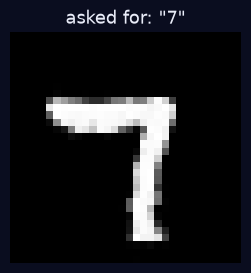

saved outputs/04_generate_7.gif


In [4]:
final, history = generate([7], seed=7, record_every=10)

import imageio.v2 as imageio
big = lambda a: np.kron(a, np.ones((8, 8), dtype=np.uint8))
frames = [big(to_np(x[0])) for _, x, _ in history]
frames += [frames[-1]] * 20                           # pause on the finished 7
imageio.mimsave(OUT / "04_generate_7.gif", frames, duration=0.05, loop=0)

plt.figure(figsize=(3, 3)); plt.imshow(final[0, 0], cmap="gray"); plt.axis("off"); plt.title('asked for: "7"'); plt.show()
print("saved outputs/04_generate_7.gif")

### Big shapes first, details last

Below, the top row is the image at each step. The bottom row is **the model's current best guess of the finished image**.
Early on, the guess is a soft blur (only the rough layout is decided). The middle steps commit to the strokes, and the last steps sharpen the details.

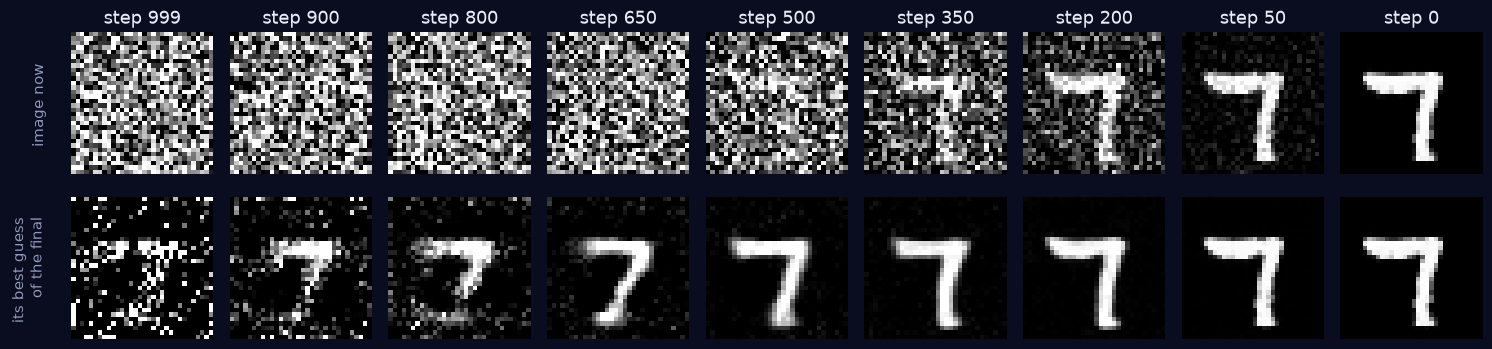

In [5]:
pick = [999, 900, 800, 650, 500, 350, 200, 50, 0]
by_t = {t: (x, g) for t, x, g in history}
fig, axes = plt.subplots(2, len(pick), figsize=(15, 3.8))
for col, t in enumerate(pick):
    x, g = by_t[t]
    axes[0, col].imshow(x[0, 0], cmap="gray"); axes[0, col].set_title(f"step {t}")
    axes[1, col].imshow(g[0, 0], cmap="gray")
for ax in axes.flat: ax.axis("off")
axes[0, 0].text(-6, 16, "image now", rotation=90, va="center", ha="right", color="#8f97ba")
axes[1, 0].text(-6, 16, "its best guess\nof the final", rotation=90, va="center", ha="right", color="#8f97ba")
plt.tight_layout(); plt.savefig(OUT / "04_coarse_to_fine.png", dpi=120); plt.show()

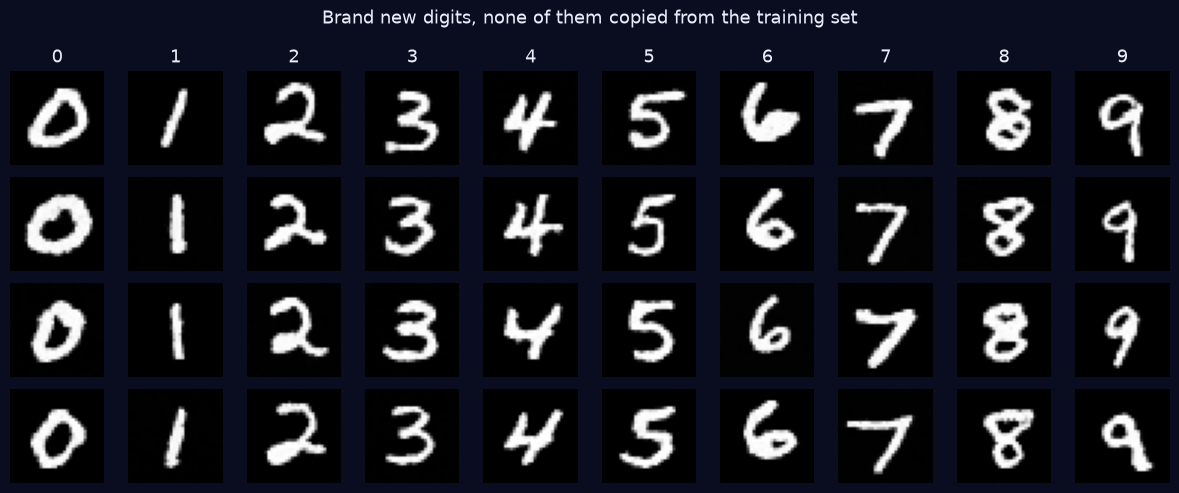

In [6]:
labels = [d for d in range(10) for _ in range(4)]
digits, _ = generate(labels, seed=3)
fig, axes = plt.subplots(4, 10, figsize=(12, 5))
for i, ax in enumerate(axes.T.flat):
    ax.imshow(digits[i, 0], cmap="gray"); ax.axis("off")
for d in range(10):
    axes[0, d].set_title(str(d))
plt.suptitle("Brand new digits, none of them copied from the training set", color="#e9ecf8")
plt.tight_layout(); plt.savefig(OUT / "04_all_digits.png", dpi=120); plt.show()

## I wondered…

These are the questions I had while learning this, each with a small experiment.

### I wondered why we remove only part of the guess, not all of it

From pure static, the model's guess is poor: it can't tell which image is underneath, so it predicts the **average of all the possibilities**, which is a blur.
If we trusted that guess and removed all the noise at once, we'd be stuck with the blur. Removing a small slice lets it look again once there's a bit of structure, and each look is sharper than the last.

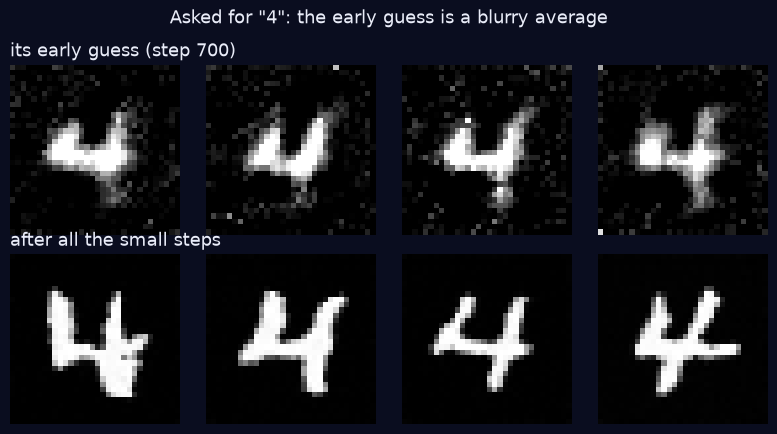

In [7]:
seeds = [11, 12, 13, 14]
fig, axes = plt.subplots(2, len(seeds), figsize=(8, 4.4))
for col, seed in enumerate(seeds):
    final, history = generate([4], seed=seed, record_every=100)
    early_guess = {t: g for t, _, g in history}[700]   # its best guess of the finished image, early on
    axes[0, col].imshow(early_guess[0, 0], cmap="gray"); axes[1, col].imshow(final[0, 0], cmap="gray")
for ax in axes.flat: ax.axis("off")
axes[0, 0].set_title("its early guess (step 700)", loc="left"); axes[1, 0].set_title("after all the small steps", loc="left")
plt.suptitle('Asked for "4": the early guess is a blurry average', color="#e9ecf8")
plt.tight_layout(); plt.savefig(OUT / "05_one_jump_vs_steps.png", dpi=120); plt.show()

### I wondered whether the structure is just its own random output

Yes. Nothing outside steers it except the label we ask for. But each guess gets pulled toward realistic digits it saw in training, like a ball rolling downhill.
**Different starting static gives a different digit; the same static gives the same digit.**

same static twice gives identical images: True


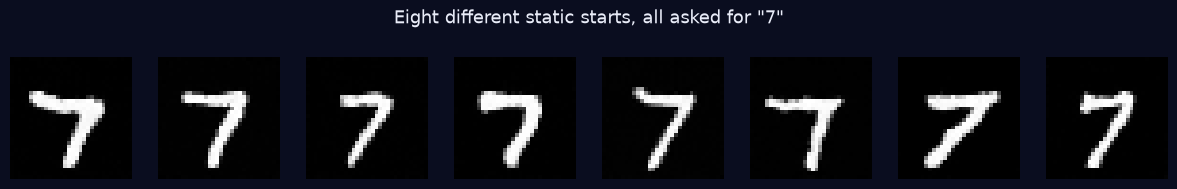

In [8]:
sevens, _ = generate([7] * 8, seed=21)
again, _ = generate([7] * 8, seed=21)
print("same static twice gives identical images:", torch.allclose(sevens, again))
fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
for ax, im in zip(axes, sevens):
    ax.imshow(im[0], cmap="gray"); ax.axis("off")
plt.suptitle('Eight different static starts, all asked for "7"', color="#e9ecf8")
plt.tight_layout(); plt.savefig(OUT / "05_different_static.png", dpi=120); plt.show()

### I wondered why the first guess isn't sharp, if every training image was sharp

The model was trained to **predict noise**, not to output finished images. That early blur is its uncertainty: an average over many possible sharp digits.
It shrinks as the picture commits to a shape. You can see it happen in the bottom row of the *big shapes first* figure above.

### I wondered whether someone told it what a "7" is

No. Real image generators train on billions of image and caption pairs. Here, each digit just came with its label (0 to 9).
Nobody explains anything; it learns that a certain label goes with certain pixel patterns.

### I wondered whether it understands words

Not like a person does. Words (here, labels) become **embeddings**: lists of numbers. In big models, similar meanings sit close together.
That list of numbers guides the model at **every** denoising step. Same static, with and without asking for a "3":

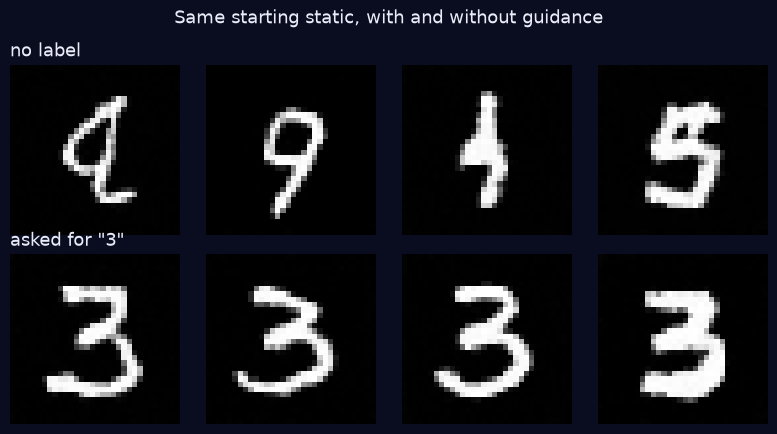

In [9]:
plain, _ = generate([TinyUNet.NO_LABEL] * 4, guidance=0, seed=31)
three, _ = generate([3] * 4, guidance=3.0, seed=31)
fig, axes = plt.subplots(2, 4, figsize=(8, 4.4))
for col in range(4):
    axes[0, col].imshow(plain[col, 0], cmap="gray"); axes[1, col].imshow(three[col, 0], cmap="gray")
for ax in axes.flat: ax.axis("off")
axes[0, 0].set_title("no label", loc="left"); axes[1, 0].set_title('asked for "3"', loc="left")
plt.suptitle("Same starting static, with and without guidance", color="#e9ecf8")
plt.tight_layout(); plt.savefig(OUT / "05_guidance.png", dpi=120); plt.show()

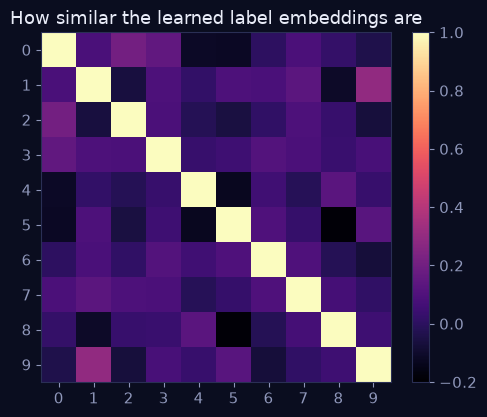

In [10]:
emb = torch.nn.functional.normalize(model.label_emb.weight[:10].detach().cpu(), dim=1)
similarity = emb @ emb.T
plt.figure(figsize=(5, 4.3))
plt.imshow(similarity, cmap="magma", vmin=-0.2, vmax=1)
plt.xticks(range(10)); plt.yticks(range(10)); plt.colorbar(fraction=0.046)
plt.title("How similar the learned label embeddings are")
plt.tight_layout(); plt.savefig(OUT / "05_label_embeddings.png", dpi=120); plt.show()

## Related facts

- **Embeddings** were made famous by **Word2vec** (Google, Tomas Mikolov and colleagues, 2013). The idea is older: a 1950s linguistics saying, *"you shall know a word by the company it keeps"* (J. R. Firth, 1957).
- In many image generators, the link between text and pictures comes from **CLIP** (OpenAI, 2021). It trains text embeddings and image embeddings to land close together when they describe the same thing.
- **Stable Diffusion** grew out of academic research on diffusion models (latent diffusion, from a university lab in Munich) and was released openly in 2022.